# Not All Imbalanced Data Needs to Be Balanced

### Overview
There is a common belief that imbalanced datasets must always be balanced using techniques like SMOTE or under-sampling. 

In this notebook, I run a quick experiment to test whether that is actually true when using strong gradient boosting models. 

I compare two identical **Stacking Classifier** setups:
- **Base Models:** XGBoost, CatBoost, and LightGBM
- **Meta-Learner:** Logistic Regression

**The Experiment:**
1. Pipeline A: **With Resampling** (SMOTE + Random Under-Sampling)
2. Pipeline B: **Without Resampling** (Raw imbalanced data)

The goal is simple: see whether balancing the data actually helps, or if training directly on the raw data yields better results (Precision, Recall, F1-Score).

In [1]:
import pandas as pd

df = pd.read_csv('creditcard.csv')

In [2]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [5]:
print("Total records:", len(df))
print("Missing values count:", df.isnull().sum().sum())
print("Duplicate records count:", df.duplicated().sum())


Total records: 284807
Missing values count: 0
Duplicate records count: 1081


In [6]:
df = df.drop_duplicates()
print("Total records after removing duplicates:", len(df))


Total records after removing duplicates: 283726


## Data Distribution


Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64
Class percentage:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


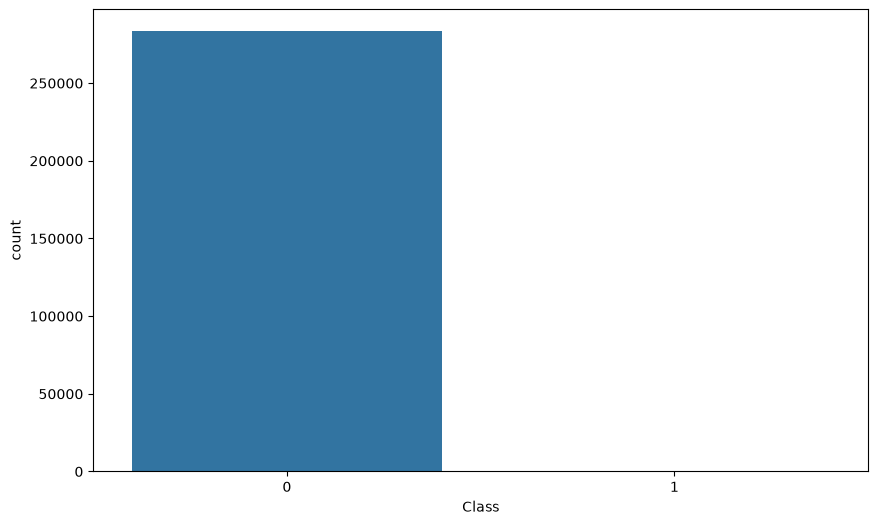

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(x='Class', data=df)

print("Class distribution:")
print(df['Class'].value_counts())

# Percentage
print("Class percentage:")
print(df['Class'].value_counts(normalize=True) * 100)


The extreme class imbalance is clearly visible here, where Class 1 (fraud) represents only a tiny fraction of the total dataset.


In [8]:
print("Class imbalance ratio: 1 :", df['Class'].value_counts(normalize=True).max() / df['Class'].value_counts(normalize=True).min())


Class imbalance ratio: 1 : 598.8435517970402


### Data Resampling

> Simulating resampling to inspect the post-resampling class distribution and evaluate potential weighting configurations for gradient boosting models.


Here, we integrate SMOTE and RandomUnderSampler directly into a pipeline. Because the features (V1–V28) are already PCA-transformed numerical components, additional feature preprocessing is not required.


In [9]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [10]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

pipelinesampling = Pipeline([
    ('smote', SMOTE(sampling_strategy=0.01, random_state=42)),
    ('under', RandomUnderSampler(sampling_strategy=0.1, random_state=42))
])

In [11]:
X_train_resampled, y_train_re_sampled = pipelinesampling.fit_resample(X_train, y_train)

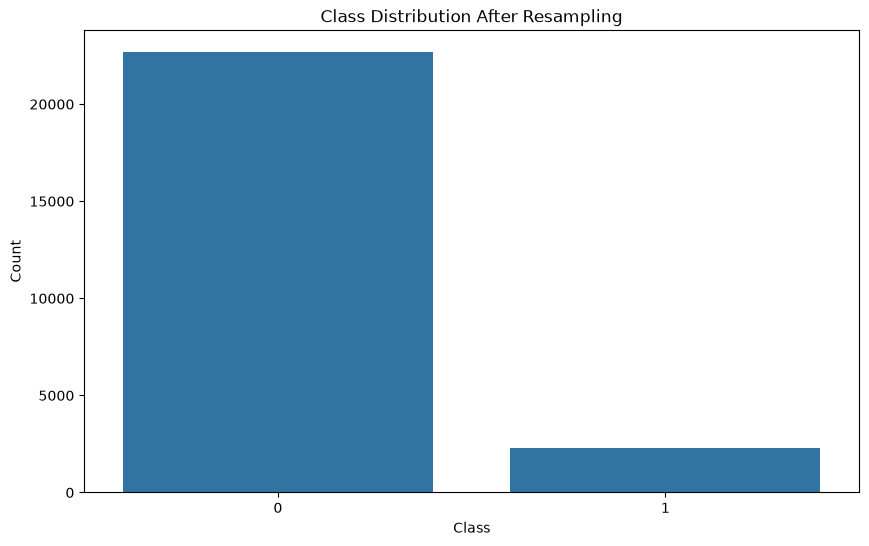

Class imbalance ratio after resampling: 1 : 10.0


In [12]:
# Class distribution after resampling
plt.figure(figsize=(10, 6))
sns.countplot(x=y_train_re_sampled)
plt.title('Class Distribution After Resampling')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

print("Class imbalance ratio after resampling: 1 :", y_train_re_sampled.value_counts(normalize=True).max() / y_train_re_sampled.value_counts(normalize=True).min())


### Building Estimators


In [13]:
# Stacking classifier with tree-based base estimators
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

    
estimators = [
    ('xgb', XGBClassifier(eval_metric='logloss', random_state=42)),
    ('cat', CatBoostClassifier(verbose=0, random_state=42)),
    ('lgbm', LGBMClassifier(random_state=42, verbose=-1))
]

stacking_model = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(), cv=5)


### Building Pipelines

Constructing pipelines **With Resampling** and **Without Resampling** to compare performance differences.


In [14]:
# Construct final pipelines (with and without resampling)
from sklearn.base import clone


pipeline = Pipeline([
    ('smote', SMOTE(sampling_strategy=0.01, random_state=42)),
    ('under', RandomUnderSampler(sampling_strategy=0.1, random_state=42)),
    ('stacking', clone(stacking_model))
])

noresamplingpipeline = Pipeline([
    ('stacking', clone(stacking_model))
])


### Model Training


In [15]:
print("Training model with resampling...")
model_with_resampling = pipeline.fit(X_train, y_train)


print("Training model without resampling...")
model_without_resampling = noresamplingpipeline.fit(X_train, y_train)


Training model with resampling...
Training model without resampling...


In [16]:
# Save models
import joblib

joblib.dump(model_with_resampling, 'model_with_resampling.pkl')
joblib.dump(model_without_resampling, 'model_without_resampling.pkl')


['model_without_resampling.pkl']

#### Evaluation Metrics


Classification Report (With Resampling):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.69      0.81      0.74        95

    accuracy                           1.00     56746
   macro avg       0.84      0.90      0.87     56746
weighted avg       1.00      1.00      1.00     56746



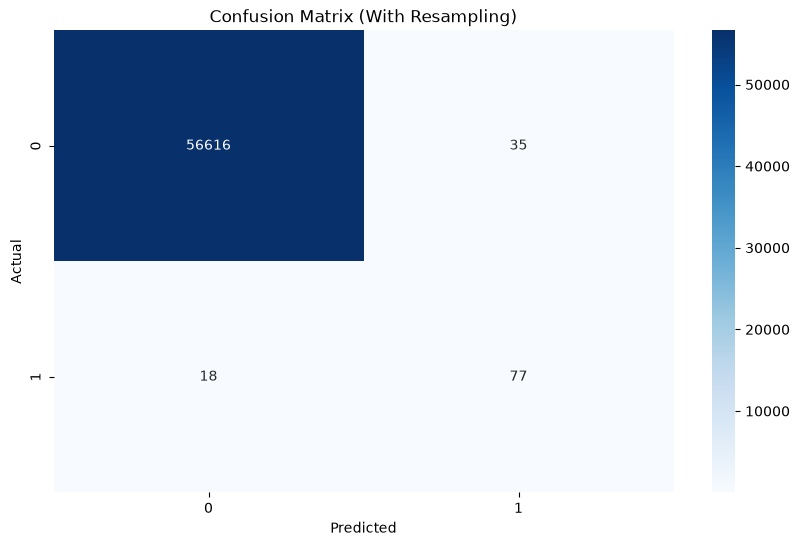

Classification Report (Without Resampling):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.72      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



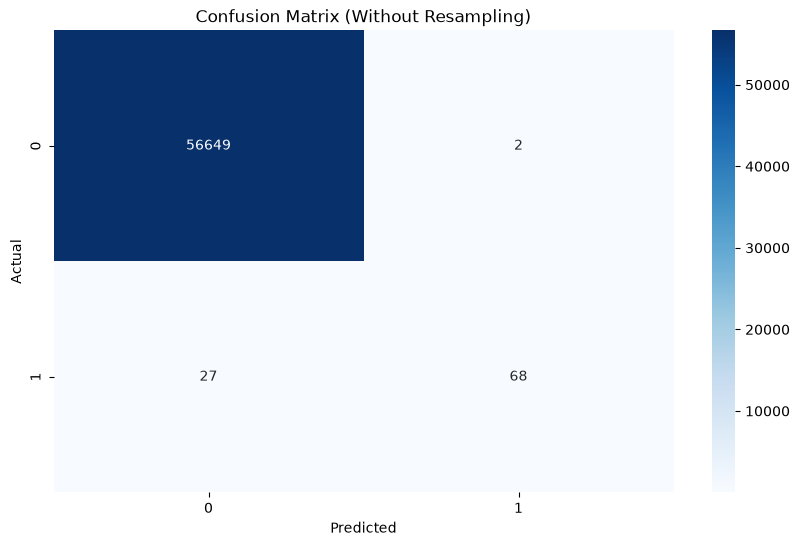

In [17]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

print("Classification Report (With Resampling):")
print(classification_report(y_test, model_with_resampling.predict(X_test)))

print("="*50)

plt.figure(figsize=(10, 6))
sns.heatmap(confusion_matrix(y_test, model_with_resampling.predict(X_test)), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (With Resampling)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print("="*50)

print("Classification Report (Without Resampling):")
print(classification_report(y_test, model_without_resampling.predict(X_test)))


print("="*50)

plt.figure(figsize=(10, 6))
sns.heatmap(confusion_matrix(y_test, model_without_resampling.predict(X_test)), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Without Resampling)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()



In [18]:
## Display metrics comparison table

df_metrics = pd.DataFrame({
    'Model': ['With Resampling', 'Without Resampling'],
    'Precision': [classification_report(y_test, model_with_resampling.predict(X_test), output_dict=True)['1']['precision'],
                  classification_report(y_test, model_without_resampling.predict(X_test), output_dict=True)['1']['precision']],
    'Recall': [classification_report(y_test, model_with_resampling.predict(X_test), output_dict=True)['1']['recall'],
               classification_report(y_test, model_without_resampling.predict(X_test), output_dict=True)['1']['recall']],
    'F1-Score': [classification_report(y_test, model_with_resampling.predict(X_test), output_dict=True)['1']['f1-score'],
                 classification_report(y_test, model_without_resampling.predict(X_test), output_dict=True)['1']['f1-score']], 
    'Accuracy': [classification_report(y_test, model_with_resampling.predict(X_test), output_dict=True)['accuracy'],
                 classification_report(y_test, model_without_resampling.predict(X_test), output_dict=True)['accuracy']],
    'Roc AUC': [roc_auc_score(y_test, model_with_resampling.predict_proba(X_test)[:, 1]),
                roc_auc_score(y_test, model_without_resampling.predict_proba(X_test)[:, 1])],
})  

df_metrics


,Model,Precision,Recall,F1-Score,Accuracy,Roc AUC
0,With Resampling,0.687500,0.810526,0.743961,0.999066,0.973786
1,Without Resampling,0.971429,0.715789,0.824242,0.999489,0.978469


### Metrics Visualization


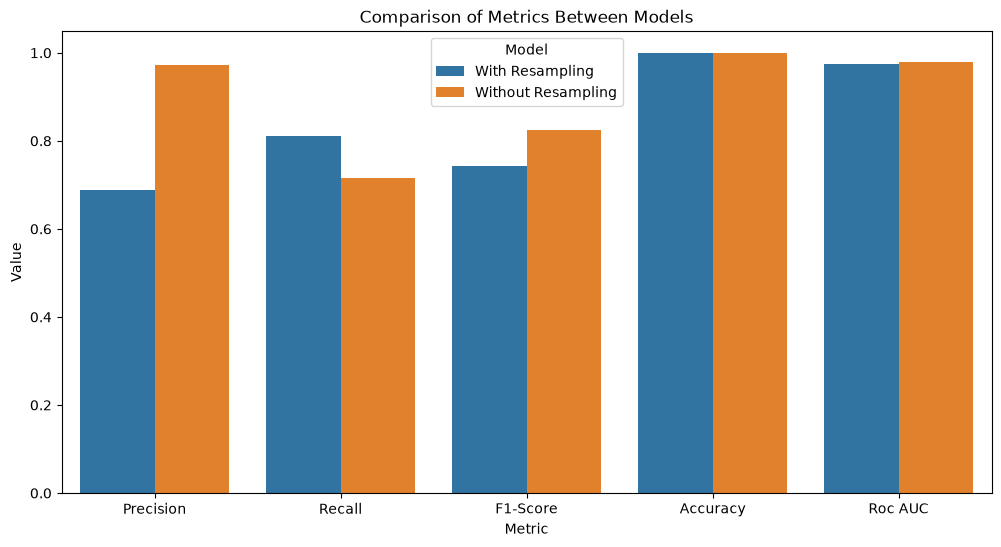

In [19]:
df_metric_long = df_metrics.melt(id_vars=['Model'], var_name='Metric', value_name='Value')

plt.figure(figsize=(12, 6))
plt.title('Comparison of Metrics Between Models')
sns.barplot(x='Metric', y='Value', hue='Model', data=df_metric_long)
plt.show()

## Conclusion

From this quick experiment comparing our Stacking Classifier (XGBoost + CatBoost + LightGBM) with and without resampling:

1. **The Precision vs. Recall Trade-off:**
   - **With Resampling (SMOTE + Under-Sampling):** Gains slightly higher Recall (~81% vs ~72%), catching a few more fraud cases. However, it triggers a flood of False Positives—causing Precision to drop hard from **~96% down to ~69%**, and dragging the overall F1-Score down to **~0.74**.
   - **Without Resampling:** Keeps False Positives very low, achieving near-perfect Precision (**~96%**) and a much higher F1-Score (**~0.82**).

2. **ROC-AUC is Virtually Identical (~0.97):**
   - The tree-based models already have strong discriminative power on their own. Resampling didn't actually help the models separate fraud better; it just forced them to be more aggressive, leading to more false alarms.

### Takeaway
**Not all imbalanced data needs to be balanced.** 

When using strong gradient boosting trees on informative features, training on the raw imbalanced data still posssible to produce a far better balance of Precision and F1-score without creating thousands of false fraud alerts for innocent users.